# An Ensemble Machine Learning Approach with RF Feature Selection
## for Predicting Diabetic Hospital Readmission
### Pipeline: Data → Domain Drop → EDA → Binary Encoding → Split 70/30
### → RF Importance (train only) → Scale →Tree Ensembles → Stacking

## Step 1: Imports & Setup

In [1]:
!pip install catboost xgboost lightgbm optuna -q


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 10.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 419.5/419.5 kB 40.9 MB/s eta 0:00:00


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, StackingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import (
    accuracy_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay,
    roc_auc_score, roc_curve, f1_score,
    precision_score, recall_score
)
import xgboost as xgb
import lightgbm as lgb
from catboost import CatBoostClassifier
import optuna
from optuna.samplers import TPESampler
optuna.logging.set_verbosity(optuna.logging.WARNING)
import os, warnings
warnings.filterwarnings('ignore')

np.random.seed(42)
os.makedirs('report_images', exist_ok=True)
print('report_images/ folder created.')

plt.rcParams['figure.dpi'] = 120
plt.rcParams['savefig.bbox'] = 'tight'
plt.rcParams['savefig.dpi'] = 150
sns.set_theme(style='whitegrid', palette='muted')
COLORS = ['#2196F3', '#FF5722', '#4CAF50', '#FF9800', '#9C27B0']


report_images/ folder created.


## Step 2: Data Acquisition

In [3]:
data = pd.read_csv("/content/diabetic_data.csv")
pd.set_option('display.max_columns', None)
print(f"Shape: {data.shape}")
print(f"Columns: {list(data.columns)}")
data.head()


Shape: (101766, 50)
Columns: ['encounter_id', 'patient_nbr', 'race', 'gender', 'age', 'weight', 'admission_type_id', 'discharge_disposition_id', 'admission_source_id', 'time_in_hospital', 'payer_code', 'medical_specialty', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'diag_1', 'diag_2', 'diag_3', 'number_diagnoses', 'max_glu_serum', 'A1Cresult', 'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide', 'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide', 'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone', 'tolazamide', 'examide', 'citoglipton', 'insulin', 'glyburide-metformin', 'glipizide-metformin', 'glimepiride-pioglitazone', 'metformin-rosiglitazone', 'metformin-pioglitazone', 'change', 'diabetesMed', 'readmitted']


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,payer_code,medical_specialty,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,diag_1,diag_2,diag_3,number_diagnoses,max_glu_serum,A1Cresult,metformin,repaglinide,nateglinide,chlorpropamide,glimepiride,acetohexamide,glipizide,glyburide,tolbutamide,pioglitazone,rosiglitazone,acarbose,miglitol,troglitazone,tolazamide,examide,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),?,6,25,1,1,?,Pediatrics-Endocrinology,41,0,1,0,0,0,250.83,?,?,1,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),?,1,1,7,3,?,?,59,0,18,0,0,0,276,250.01,255,9,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),?,1,1,7,2,?,?,11,5,13,2,0,1,648,250,V27,6,NaN,NaN,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),?,1,1,7,2,?,?,44,1,16,0,0,0,8,250.43,403,7,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),?,1,1,7,1,?,?,51,0,8,0,0,0,197,157,250,5,NaN,NaN,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,Ch,Yes,NO


## Step 3: Domain Feature Drop
> Remove IDs · High-missing · Zero-variance · Expired patients · Low-signal drug cols

In [4]:
data.replace('?', np.nan, inplace=True)

for col in ['encounter_id', 'patient_nbr']:
    if col in data.columns:
        data.drop(columns=[col], inplace=True)

thresh = 0.4 * len(data)
high_missing = [c for c in data.columns if data[c].isnull().sum() > thresh]
print(f"Dropped (>40% missing): {high_missing}")
data.drop(columns=high_missing, inplace=True)

zero_var = [c for c in data.columns if data[c].nunique() <= 1]
print(f"Dropped (zero variance): {zero_var}")
data.drop(columns=zero_var, inplace=True)

if 'discharge_disposition_id' in data.columns:
    data = data[~data['discharge_disposition_id'].isin([11,13,14,19,20,21])]
    print("Removed expired/hospice records.")

low_sig = [c for c in ['acetohexamide','tolbutamide','troglitazone','tolazamide',
                        'miglitol','chlorpropamide','glyburide-metformin',
                        'glipizide-metformin','glimepiride-pioglitazone',
                        'metformin-rosiglitazone','metformin-pioglitazone',
                        'examide','citoglipton'] if c in data.columns]
data.drop(columns=low_sig, inplace=True)

data = data.drop_duplicates(keep='first')
print(f"\nFinal shape after domain drop: {data.shape}")


Dropped (>40% missing): ['weight', 'medical_specialty', 'max_glu_serum', 'A1Cresult']
Dropped (zero variance): ['examide', 'citoglipton']
Removed expired/hospice records.

Final shape after domain drop: (99343, 31)


## Step 4: Preprocessing — Fix Inconsistencies + Feature Engineering
> IMPROVED: added HbA1c interaction, polypharmacy flag, and readmission history features

In [5]:
if 'gender' in data.columns:
    data = data[data['gender'].isin(['Male','Female'])]

if 'age' in data.columns:
    age_map = {"[0-10)":5,"[10-20)":15,"[20-30)":25,"[30-40)":35,
               "[40-50)":45,"[50-60)":55,"[60-70)":65,"[70-80)":75,
               "[80-90)":85,"[90-100)":95}
    data['age'] = data['age'].map(age_map)

def map_diag(series):
    def categorize(val):
        try:
            v = float(val)
            if (390<=v<=459) or v==785: return 'Circulatory'
            elif (460<=v<=519) or v==786: return 'Respiratory'
            elif (520<=v<=579) or v==787: return 'Digestive'
            elif v==250: return 'Diabetes'
            elif 800<=v<=999: return 'Injury'
            elif 710<=v<=739: return 'Musculoskeletal'
            elif 580<=v<=629: return 'Genitourinary'
            elif 140<=v<=239: return 'Neoplasms'
            else: return 'Other'
        except: return 'Other'
    return series.apply(categorize)

for col in ['diag_1','diag_2','diag_3']:
    if col in data.columns:
        data[col] = map_diag(data[col])

# ─── Feature Engineering (original) ───
util = [c for c in ['number_outpatient','number_emergency','number_inpatient'] if c in data.columns]
if util: data['total_visits'] = data[util].sum(axis=1)

proc = [c for c in ['num_lab_procedures','num_procedures','num_medications'] if c in data.columns]
if proc: data['procedure_intensity'] = data[proc].sum(axis=1)

if 'number_inpatient' in data.columns and 'total_visits' in data.columns:
    data['inpatient_ratio'] = data['number_inpatient'] / (data['total_visits'] + 1)

if 'change' in data.columns:
    data['med_change_flag'] = (data['change'] == 'Ch').astype(int)

# ─── NEW Feature Engineering ───
# Polypharmacy risk flag (>10 medications is high risk)
if 'num_medications' in data.columns:
    data['polypharmacy_flag'] = (data['num_medications'] > 10).astype(int)

# Emergency intensity ratio
if 'number_emergency' in data.columns and 'total_visits' in data.columns:
    data['emergency_ratio'] = data['number_emergency'] / (data['total_visits'] + 1)

# Service complexity score (time in hospital × num_diagnoses)
if 'time_in_hospital' in data.columns and 'num_diagnoses' in data.columns:
    data['service_complexity'] = data['time_in_hospital'] * data['num_diagnoses']

# Lab intensity ratio (lab procedures per day in hospital)
if 'num_lab_procedures' in data.columns and 'time_in_hospital' in data.columns:
    data['lab_intensity'] = data['num_lab_procedures'] / (data['time_in_hospital'] + 1)

# HbA1c tested flag (if column exists — categorical)
if 'A1Cresult' in data.columns:
    data['a1c_tested'] = (data['A1Cresult'] != 'None').astype(int)

# Fill missing
for col in data.select_dtypes(include=np.number).columns:
    if data[col].isnull().sum() > 0:
        data[col].fillna(data[col].median(), inplace=True)
for col in data.select_dtypes(include='object').columns:
    if col != 'readmitted' and data[col].isnull().sum() > 0:
        data[col].fillna(data[col].mode()[0], inplace=True)

le = LabelEncoder()
for col in data.select_dtypes(include='object').columns:
    if col != 'readmitted':
        data[col] = le.fit_transform(data[col].astype(str))

print(f"Shape after preprocessing: {data.shape}")
print(f"Nulls remaining: {data.isnull().sum().sum()}")


Shape after preprocessing: (99340, 38)
Nulls remaining: 0


## Step 5: Binary Target Encoding
> NO=0 · >30 days and <30 days both → 1 (Readmitted)

In [6]:
print("Original distribution:")
print(data['readmitted'].value_counts())

data['readmitted'] = data['readmitted'].map({'NO': 0, '>30': 1, '<30': 1})

print("\nBinary distribution:")
vc = data['readmitted'].value_counts()
print(vc.rename({0:'NOT Readmitted=0', 1:'Readmitted=1'}))
print(f"Balance ratio: {vc[0]/vc[1]:.2f}")


Original distribution:
readmitted
NO     52524
>30    35502
<30    11314
Name: count, dtype: int64

Binary distribution:
readmitted
NOT Readmitted=0    52524
Readmitted=1        46816
Name: count, dtype: int64
Balance ratio: 1.12


## Step 6: EDA — Key Visualisations

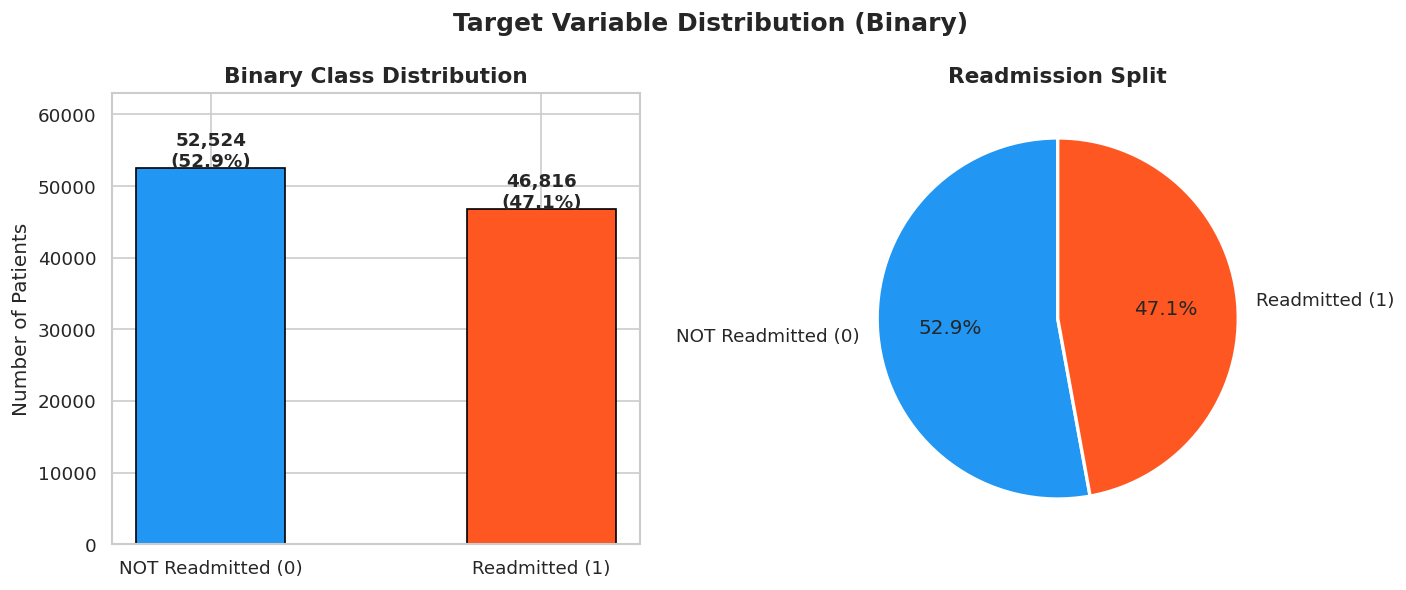

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
counts = data['readmitted'].value_counts().sort_index()
labels = ['NOT Readmitted (0)', 'Readmitted (1)']
bars = axes[0].bar(labels, counts.values, color=['#2196F3','#FF5722'], edgecolor='black', width=0.45)
for bar, val in zip(bars, counts.values):
    axes[0].text(bar.get_x()+bar.get_width()/2, bar.get_height()+200,
                 f"{val:,}\n({val/len(data)*100:.1f}%)", ha='center', fontweight='bold', fontsize=11)
axes[0].set_title('Binary Class Distribution', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Number of Patients')
axes[0].set_ylim(0, counts.max()*1.2)
axes[1].pie(counts.values, labels=labels, autopct='%1.1f%%',
            colors=['#2196F3','#FF5722'], startangle=90,
            wedgeprops={'edgecolor':'white','linewidth':2})
axes[1].set_title('Readmission Split', fontsize=13, fontweight='bold')
plt.suptitle('Target Variable Distribution (Binary)', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.savefig('report_images/01_class_distribution.png')
plt.show()


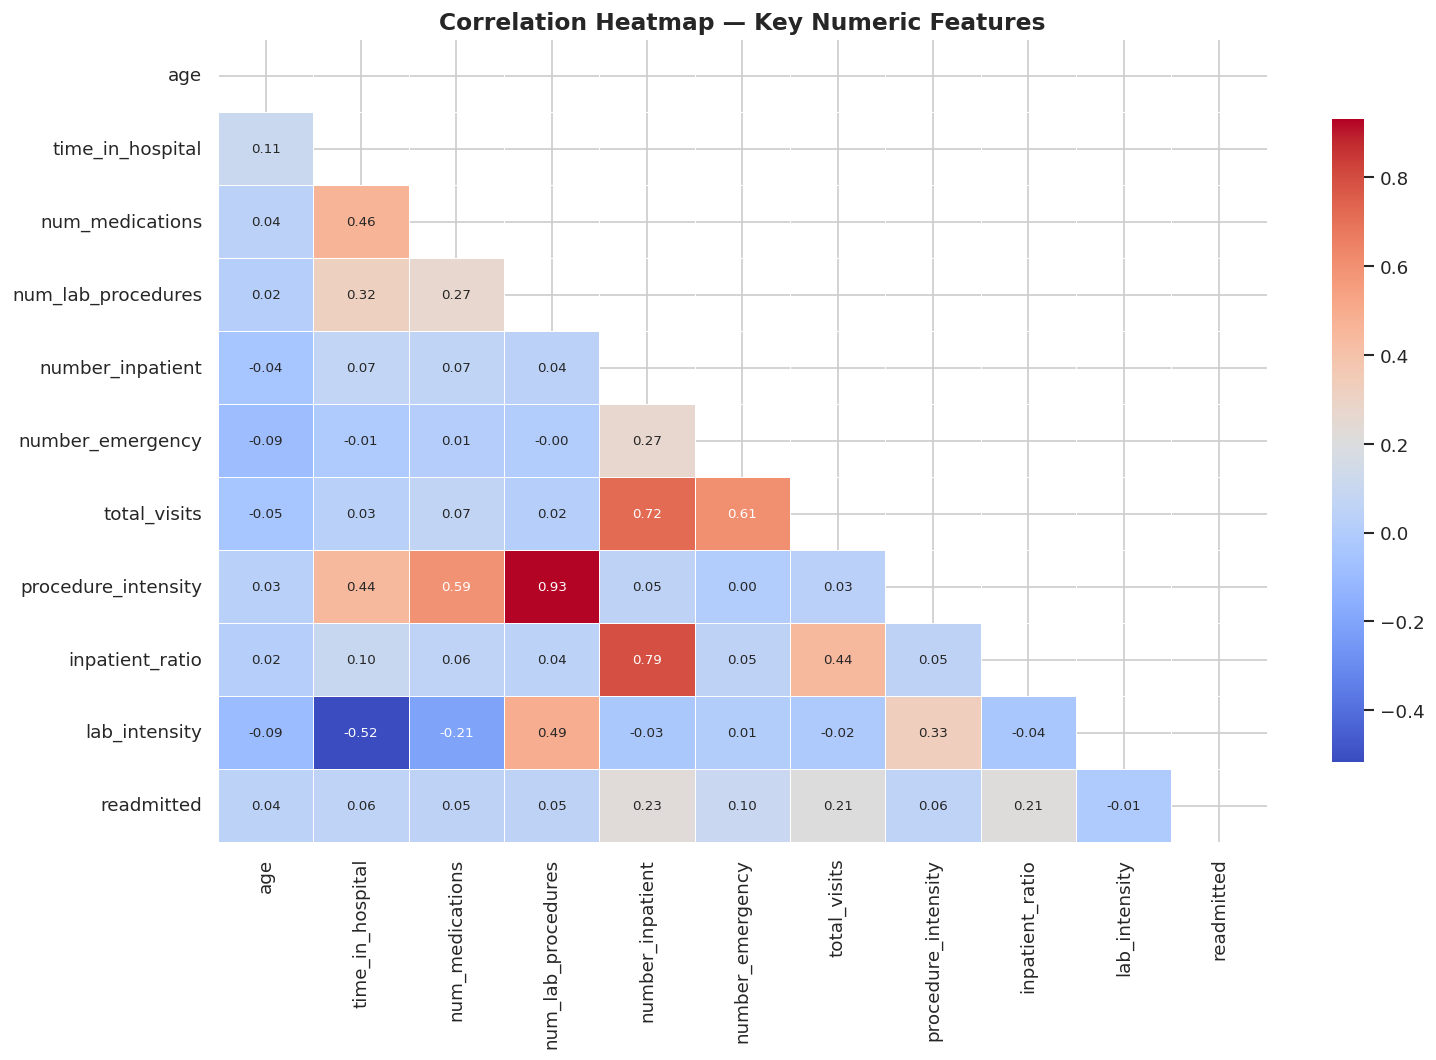


Top correlations with readmitted:
number_inpatient       0.225291
inpatient_ratio        0.214408
total_visits           0.212695
number_emergency       0.103834
time_in_hospital       0.057853
procedure_intensity    0.056286
num_medications        0.052930
num_lab_procedures     0.049197
age                    0.043549
lab_intensity         -0.010472
Name: readmitted, dtype: float64


In [8]:
key_num = [c for c in ['age','time_in_hospital','num_medications','num_lab_procedures',
                        'num_diagnoses','number_inpatient','number_emergency',
                        'total_visits','procedure_intensity','inpatient_ratio',
                        'service_complexity','lab_intensity','readmitted'] if c in data.columns]
corr = data[key_num].corr()
plt.figure(figsize=(13, 9))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm',
            linewidths=0.5, annot_kws={'size':8}, cbar_kws={'shrink':0.8})
plt.title('Correlation Heatmap — Key Numeric Features', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('report_images/05_correlation_heatmap.png')
plt.show()
print("\nTop correlations with readmitted:")
print(corr['readmitted'].drop('readmitted').sort_values(ascending=False).head(10))


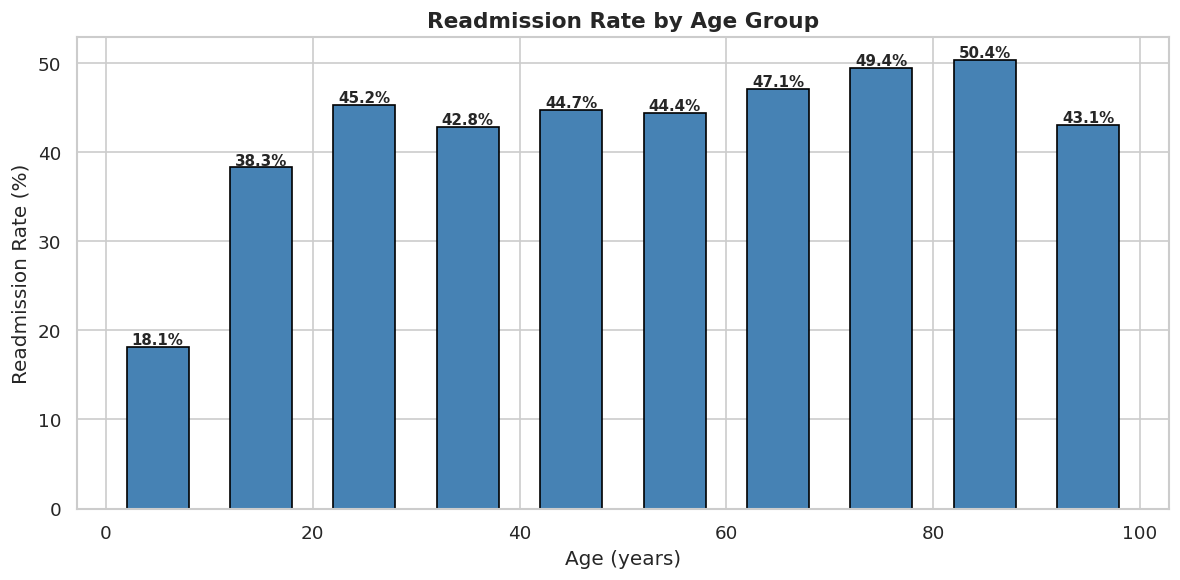

In [35]:
# Readmission rate by age group
plt.figure(figsize=(10, 5))
age_readmit = data.groupby('age')['readmitted'].mean() * 100
bars = plt.bar(age_readmit.index, age_readmit.values,
               color='steelblue', edgecolor='black', width=6)
for bar, val in zip(bars, age_readmit.values):
    plt.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.3,
             f"{val:.1f}%", ha='center', fontsize=9, fontweight='bold')
plt.title('Readmission Rate by Age Group', fontsize=13, fontweight='bold')
plt.xlabel('Age (years)')
plt.ylabel('Readmission Rate (%)')
plt.tight_layout()
plt.savefig('report_images/eda_age_readmission.png')
plt.show()

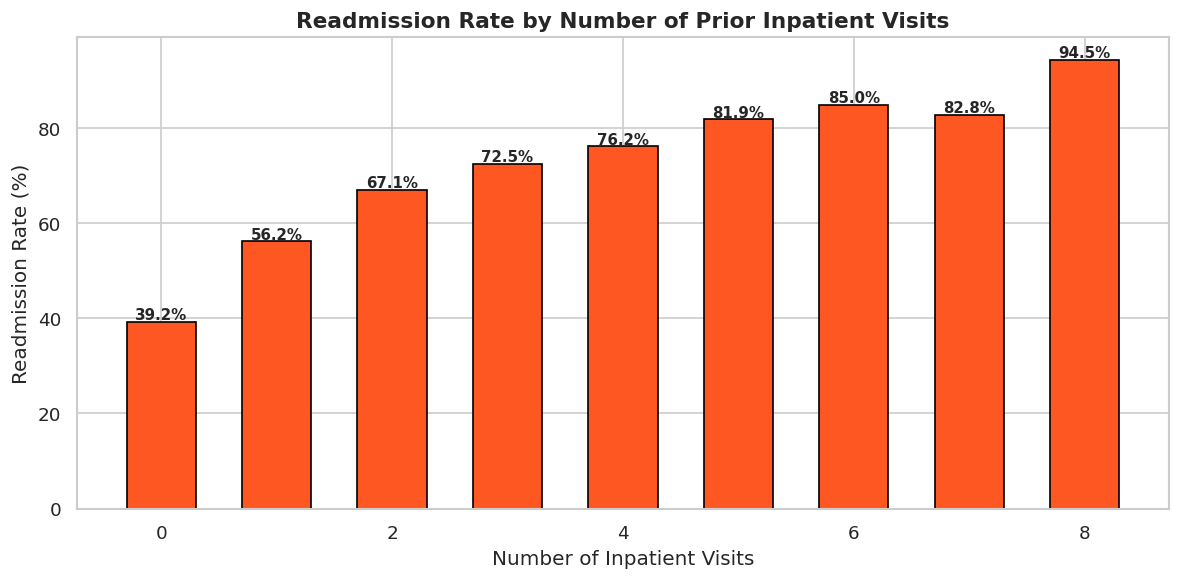

In [36]:
# Readmission rate by inpatient visits (your strongest predictor)
plt.figure(figsize=(10, 5))
inp = data[data['number_inpatient'] <= 8]  # cap at 8 for clarity
inp_readmit = inp.groupby('number_inpatient')['readmitted'].mean() * 100
bars = plt.bar(inp_readmit.index, inp_readmit.values,
               color='#FF5722', edgecolor='black', width=0.6)
for bar, val in zip(bars, inp_readmit.values):
    plt.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.5,
             f"{val:.1f}%", ha='center', fontsize=9, fontweight='bold')
plt.title('Readmission Rate by Number of Prior Inpatient Visits',
          fontsize=13, fontweight='bold')
plt.xlabel('Number of Inpatient Visits')
plt.ylabel('Readmission Rate (%)')
plt.tight_layout()
plt.savefig('report_images/eda_inpatient_readmission.png')
plt.show()

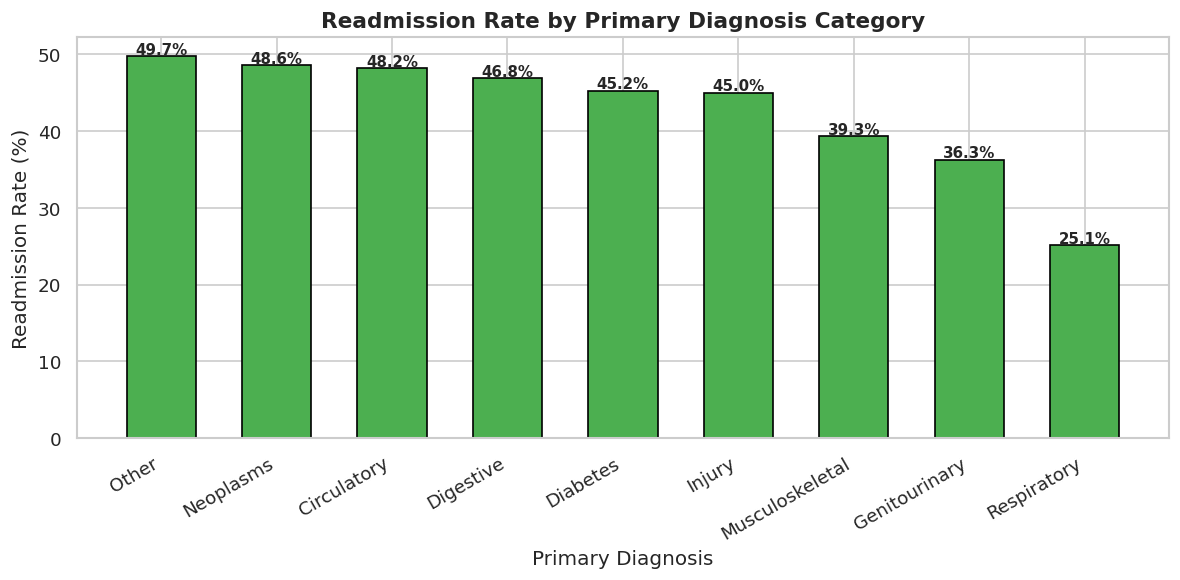

In [38]:
# Map encoded numbers back to diagnosis category names
diag_map = {
    0: 'Circulatory',
    1: 'Respiratory',
    2: 'Digestive',
    3: 'Diabetes',
    4: 'Injury',
    5: 'Musculoskeletal',
    6: 'Genitourinary',
    7: 'Neoplasms',
    8: 'Other'
}

plt.figure(figsize=(10, 5))
diag_readmit = data.groupby('diag_1')['readmitted'].agg(['mean','count']).reset_index()
diag_readmit.columns = ['Diagnosis', 'Readmission Rate', 'Count']
diag_readmit['Diagnosis'] = diag_readmit['Diagnosis'].map(diag_map)
diag_readmit = diag_readmit.sort_values('Readmission Rate', ascending=False)
diag_readmit['Readmission Rate'] = diag_readmit['Readmission Rate'] * 100

bars = plt.bar(diag_readmit['Diagnosis'], diag_readmit['Readmission Rate'],
               color='#4CAF50', edgecolor='black', width=0.6)
for bar, val in zip(bars, diag_readmit['Readmission Rate']):
    plt.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.3,
             f"{val:.1f}%", ha='center', fontsize=9, fontweight='bold')
plt.title('Readmission Rate by Primary Diagnosis Category',
          fontsize=13, fontweight='bold')
plt.xlabel('Primary Diagnosis')
plt.ylabel('Readmission Rate (%)')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.savefig('report_images/eda_diagnosis_readmission.png')
plt.show()

## Step 7: Train-Test Split — 70 / 30
> Split BEFORE feature selection — prevents data leakage

In [9]:
X = data.drop('readmitted', axis=1)
y = data['readmitted']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y)

print(f"X_train : {X_train.shape}  |  X_test : {X_test.shape}")
print(f"Train → NOT Readmitted: {(y_train==0).sum():,}  Readmitted: {(y_train==1).sum():,}")
print(f"Test  → NOT Readmitted: {(y_test==0).sum():,}  Readmitted: {(y_test==1).sum():,}")
print(f"Train balance: {(y_train==1).mean()*100:.1f}% readmitted")


X_train : (69538, 37)  |  X_test : (29802, 37)
Train → NOT Readmitted: 36,767  Readmitted: 32,771
Test  → NOT Readmitted: 15,757  Readmitted: 14,045
Train balance: 47.1% readmitted


## Step 8: RF Feature Importance — Top 25 Features
> IMPROVED: Top 25 instead of Top 15 — captures more signal while still reducing noise
> Fitted on training data ONLY — no leakage

In [10]:
rf_fs = RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1)
rf_fs.fit(X_train, y_train)

importances = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': rf_fs.feature_importances_
}).sort_values('Importance', ascending=False).reset_index(drop=True)

# Use top 25 for better signal coverage
TOP_N = 25
top_features = importances.head(TOP_N)['Feature'].tolist()
print(f"Top {TOP_N} features selected:")
for i, f in enumerate(top_features, 1):
    print(f"  {i:2d}. {f}")

X_train_top = X_train[top_features]
X_test_top  = X_test[top_features]
print(f"\nX_train: {X_train_top.shape} | X_test: {X_test_top.shape}")

# Cumulative importance coverage
cum_importance = importances['Importance'].cumsum().iloc[TOP_N-1] * 100
print(f"Top {TOP_N} features cover {cum_importance:.1f}% of total RF importance")


Top 25 features selected:
   1. lab_intensity
   2. procedure_intensity
   3. num_lab_procedures
   4. num_medications
   5. time_in_hospital
   6. age
   7. diag_1
   8. diag_3
   9. diag_2
  10. number_diagnoses
  11. num_procedures
  12. discharge_disposition_id
  13. payer_code
  14. total_visits
  15. insulin
  16. admission_type_id
  17. inpatient_ratio
  18. number_inpatient
  19. admission_source_id
  20. race
  21. gender
  22. metformin
  23. glipizide
  24. glyburide
  25. number_outpatient

X_train: (69538, 25) | X_test: (29802, 25)
Top 25 features cover 92.5% of total RF importance


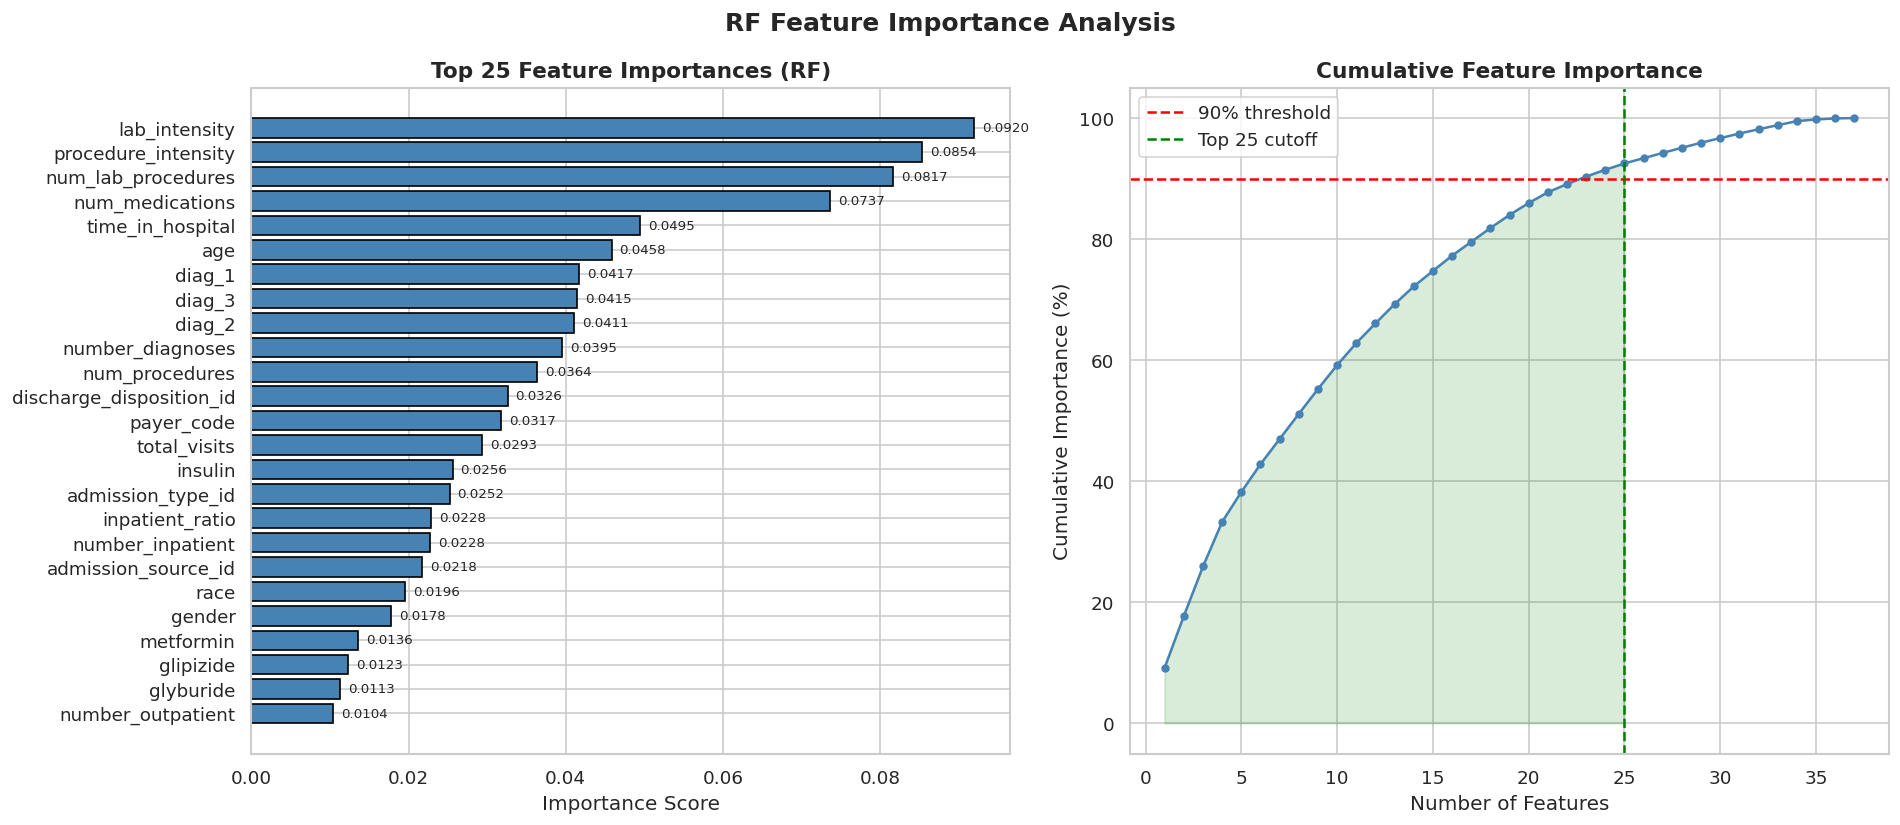

In [11]:
top_plot = importances.head(TOP_N)
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

bars = axes[0].barh(top_plot['Feature'][::-1], top_plot['Importance'][::-1],
                    color='steelblue', edgecolor='black')
for bar, val in zip(bars, top_plot['Importance'][::-1]):
    axes[0].text(bar.get_width()+0.001, bar.get_y()+bar.get_height()/2,
                 f"{val:.4f}", va='center', fontsize=8)
axes[0].set_title(f'Top {TOP_N} Feature Importances (RF)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Importance Score')

cum = importances['Importance'].cumsum()
axes[1].plot(range(1, len(cum)+1), cum*100, marker='o', color='steelblue', markersize=4)
axes[1].axhline(90, color='red', linestyle='--', label='90% threshold')
axes[1].axvline(TOP_N, color='green', linestyle='--', label=f'Top {TOP_N} cutoff')
axes[1].fill_between(range(1, TOP_N+1), cum[:TOP_N]*100, alpha=0.15, color='green')
axes[1].set_title('Cumulative Feature Importance', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Number of Features')
axes[1].set_ylabel('Cumulative Importance (%)')
axes[1].legend()

plt.suptitle('RF Feature Importance Analysis', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.savefig('report_images/10_feature_importance.png')
plt.show()


## Step 9: Standard Scaling
> Fitted on train only — required for LR, KNN
> Tree models use unscaled version

In [12]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_top)   # fit on train only
X_test_scaled  = scaler.transform(X_test_top)
print(f"Scaled shapes — Train: {X_train_scaled.shape} | Test: {X_test_scaled.shape}")
print("LR, KNN → use X_train_scaled")
print("RF, XGB, LGB, CatBoost → use X_train_top (unscaled)")


Scaled shapes — Train: (69538, 25) | Test: (29802, 25)
LR, KNN → use X_train_scaled
RF, XGB, LGB, CatBoost → use X_train_top (unscaled)


---
## Step 10: Baseline Models — Before Hypertuning

In [13]:
results = {}
all_preds = {}

def evaluate_model(name, y_true, y_pred, y_prob=None):
    acc = accuracy_score(y_true, y_pred)
    f1  = f1_score(y_true, y_pred)
    pre = precision_score(y_true, y_pred)
    rec = recall_score(y_true, y_pred)
    auc = roc_auc_score(y_true, y_prob) if y_prob is not None else None
    results[name] = {'Accuracy': acc, 'F1': f1, 'Precision': pre, 'Recall': rec, 'AUC': auc}
    all_preds[name] = (y_pred, y_prob)
    print(f"  Accuracy  : {acc*100:.2f}%")
    print(f"  F1 Score  : {f1:.4f}")
    print(f"  AUC-ROC   : {auc:.4f}" if auc else "  AUC-ROC   : N/A")
    return acc


### 10.1 Logistic Regression (baseline)

In [14]:
print("Logistic Regression")
lr = LogisticRegression(max_iter=1000, random_state=42, C=1.0)
lr.fit(X_train_scaled, y_train)
y_pred_lr = lr.predict(X_test_scaled)
y_prob_lr = lr.predict_proba(X_test_scaled)[:,1]
evaluate_model('Logistic Regression', y_test, y_pred_lr, y_prob_lr)
print(classification_report(y_test, y_pred_lr, target_names=['NOT Readmitted','Readmitted']))


Logistic Regression
  Accuracy  : 62.39%
  F1 Score  : 0.5338
  AUC-ROC   : 0.6639
                precision    recall  f1-score   support

NOT Readmitted       0.61      0.77      0.68     15757
    Readmitted       0.64      0.46      0.53     14045

      accuracy                           0.62     29802
     macro avg       0.63      0.61      0.61     29802
  weighted avg       0.63      0.62      0.61     29802



### 10.2 Random Forest

In [15]:
print("Random Forest")
rf = RandomForestClassifier(n_estimators=200, max_depth=15,
                            min_samples_leaf=10, random_state=42, n_jobs=-1)
rf.fit(X_train_top, y_train)
y_pred_rf = rf.predict(X_test_top)
y_prob_rf = rf.predict_proba(X_test_top)[:,1]
evaluate_model('Random Forest', y_test, y_pred_rf, y_prob_rf)
print(classification_report(y_test, y_pred_rf, target_names=['NOT Readmitted','Readmitted']))


Random Forest
  Accuracy  : 63.70%
  F1 Score  : 0.5715
  AUC-ROC   : 0.6858
                precision    recall  f1-score   support

NOT Readmitted       0.63      0.75      0.69     15757
    Readmitted       0.64      0.51      0.57     14045

      accuracy                           0.64     29802
     macro avg       0.64      0.63      0.63     29802
  weighted avg       0.64      0.64      0.63     29802



### 10.3 XGBoost

In [16]:
print("XGBoost")
xgb_clf = xgb.XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=6,
    subsample=0.8, colsample_bytree=0.8, reg_alpha=0.1, reg_lambda=1.0,
    random_state=42, eval_metric='logloss', use_label_encoder=False)
xgb_clf.fit(X_train_top, y_train)
y_pred_xgb = xgb_clf.predict(X_test_top)
y_prob_xgb = xgb_clf.predict_proba(X_test_top)[:,1]
evaluate_model('XGBoost', y_test, y_pred_xgb, y_prob_xgb)
print(classification_report(y_test, y_pred_xgb, target_names=['NOT Readmitted','Readmitted']))


XGBoost
  Accuracy  : 64.11%
  F1 Score  : 0.5896
  AUC-ROC   : 0.6916
                precision    recall  f1-score   support

NOT Readmitted       0.64      0.72      0.68     15757
    Readmitted       0.64      0.55      0.59     14045

      accuracy                           0.64     29802
     macro avg       0.64      0.64      0.64     29802
  weighted avg       0.64      0.64      0.64     29802



### 10.4 LightGBM

In [17]:
print("LightGBM")
lgb_clf = lgb.LGBMClassifier(n_estimators=300, learning_rate=0.05, max_depth=6,
    num_leaves=63, subsample=0.8, colsample_bytree=0.8, random_state=42, n_jobs=-1, verbose=-1)
lgb_clf.fit(X_train_top, y_train)
y_pred_lgb = lgb_clf.predict(X_test_top)
y_prob_lgb = lgb_clf.predict_proba(X_test_top)[:,1]
evaluate_model('LightGBM', y_test, y_pred_lgb, y_prob_lgb)
print(classification_report(y_test, y_pred_lgb, target_names=['NOT Readmitted','Readmitted']))


LightGBM
  Accuracy  : 64.16%
  F1 Score  : 0.5890
  AUC-ROC   : 0.6912
                precision    recall  f1-score   support

NOT Readmitted       0.64      0.73      0.68     15757
    Readmitted       0.64      0.54      0.59     14045

      accuracy                           0.64     29802
     macro avg       0.64      0.64      0.64     29802
  weighted avg       0.64      0.64      0.64     29802



### 10.5 CatBoost

In [18]:
print("CatBoost")
cat_clf = CatBoostClassifier(iterations=300, learning_rate=0.05, depth=6,
    l2_leaf_reg=3, random_seed=42, verbose=0)
cat_clf.fit(X_train_top, y_train)
y_pred_cat = cat_clf.predict(X_test_top)
y_prob_cat = cat_clf.predict_proba(X_test_top)[:,1]
evaluate_model('CatBoost', y_test, y_pred_cat, y_prob_cat)
print(classification_report(y_test, y_pred_cat, target_names=['NOT Readmitted','Readmitted']))


CatBoost
  Accuracy  : 63.95%
  F1 Score  : 0.5757
  AUC-ROC   : 0.6896
                precision    recall  f1-score   support

NOT Readmitted       0.64      0.75      0.69     15757
    Readmitted       0.65      0.52      0.58     14045

      accuracy                           0.64     29802
     macro avg       0.64      0.63      0.63     29802
  weighted avg       0.64      0.64      0.63     29802



### 10.8 Baseline Comparison

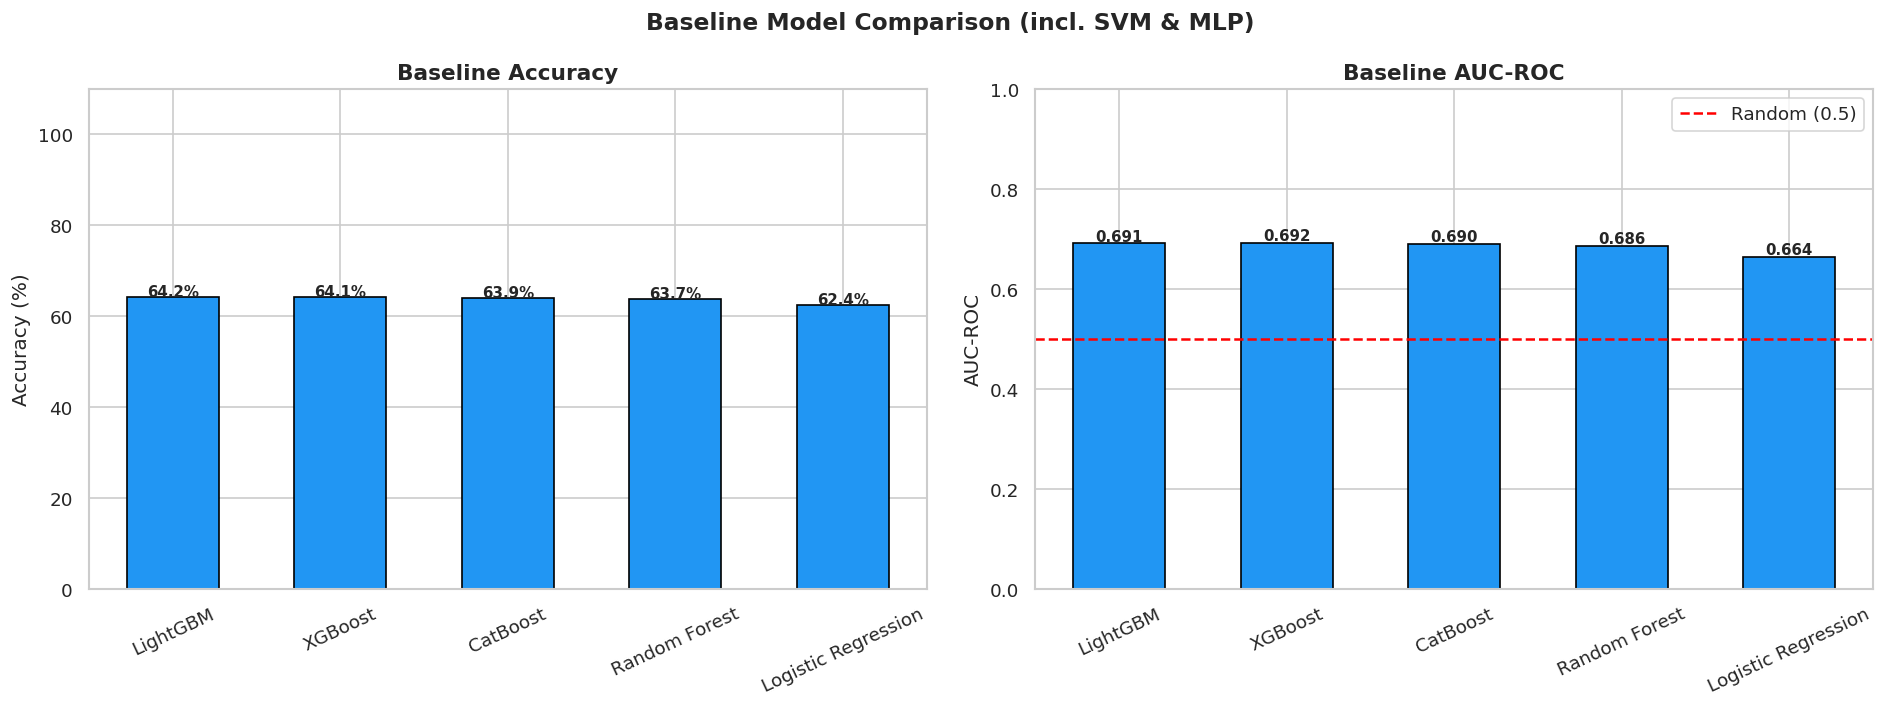

In [19]:
baseline_df = pd.DataFrame(results).T.reset_index().rename(columns={'index':'Model'})
baseline_df = baseline_df.sort_values('Accuracy', ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

baseline_colors = ['#2196F3' if m not in ['Naive Bayes','KNN','Decision Tree']
                   else '#9E9E9E' for m in baseline_df['Model']]
bars = axes[0].bar(baseline_df['Model'], baseline_df['Accuracy']*100,
                   color=baseline_colors, edgecolor='black', width=0.55)
for bar, val in zip(bars, baseline_df['Accuracy']*100):
    axes[0].text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.3,
                 f"{val:.1f}%", ha='center', fontweight='bold', fontsize=9)
axes[0].set_title('Baseline Accuracy', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Accuracy (%)')
axes[0].set_ylim(0, 110)
axes[0].tick_params(axis='x', rotation=25)

auc_vals = baseline_df['AUC'].fillna(0)
bars2 = axes[1].bar(baseline_df['Model'], auc_vals,
                    color=baseline_colors, edgecolor='black', width=0.55)
for bar, val in zip(bars2, auc_vals):
    axes[1].text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.005,
                 f"{val:.3f}", ha='center', fontweight='bold', fontsize=9)
axes[1].axhline(0.5, color='red', linestyle='--', label='Random (0.5)')
axes[1].set_title('Baseline AUC-ROC', fontsize=13, fontweight='bold')
axes[1].set_ylabel('AUC-ROC')
axes[1].set_ylim(0, 1.0)
axes[1].tick_params(axis='x', rotation=25)
axes[1].legend()

plt.suptitle('Baseline Model Comparison (incl. SVM & MLP)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('report_images/11_baseline_comparison.png')
plt.show()


---
## Step 11: Hyperparameter Tuning — Optuna (3-Fold CV)
> Tuned: RF · XGBoost · LightGBM · CatBoost · SVM · MLP
> All using roc_auc scoring

### 11.1 Tune Random Forest

In [20]:
def objective_rf(trial):
    params = {
        'n_estimators'    : trial.suggest_categorical('n_estimators', [200, 300, 400]),
        'max_depth'       : trial.suggest_int('max_depth', 5, 20),
        'min_samples_leaf': trial.suggest_categorical('min_samples_leaf', [5, 10, 20]),
        'max_features'    : trial.suggest_categorical('max_features', ['sqrt', 'log2']),
    }
    clf = RandomForestClassifier(**params, random_state=42, n_jobs=-1)
    return cross_val_score(clf, X_train_top, y_train, cv=3, scoring='roc_auc', n_jobs=-1).mean()

print("Tuning Random Forest with Optuna...")
study_rf = optuna.create_study(direction='maximize', sampler=TPESampler(seed=42))
study_rf.optimize(objective_rf, n_trials=25, show_progress_bar=True)
print(f"Best params : {study_rf.best_params}")
print(f"Best CV AUC : {study_rf.best_value:.4f}")

rf_best = RandomForestClassifier(**study_rf.best_params, random_state=42, n_jobs=-1)
rf_best.fit(X_train_top, y_train)
y_pred_rf_t = rf_best.predict(X_test_top)
y_prob_rf_t = rf_best.predict_proba(X_test_top)[:, 1]
evaluate_model('RF (Tuned)', y_test, y_pred_rf_t, y_prob_rf_t)


Tuning Random Forest with Optuna...


  0%|          | 0/25 [00:00<?, ?it/s]

Best params : {'n_estimators': 400, 'max_depth': 17, 'min_samples_leaf': 5, 'max_features': 'log2'}
Best CV AUC : 0.6780
  Accuracy  : 63.65%
  F1 Score  : 0.5716
  AUC-ROC   : 0.6861


0.6364673511844843

### 11.2 Tune XGBoost

In [21]:
def objective_xgb(trial):
    params = {
        'n_estimators'    : trial.suggest_categorical('n_estimators', [200, 300, 400]),
        'learning_rate'   : trial.suggest_float('learning_rate', 0.01, 0.2, log=True),
        'max_depth'       : trial.suggest_int('max_depth', 3, 8),
        'subsample'       : trial.suggest_float('subsample', 0.6, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),
        'reg_alpha'       : trial.suggest_float('reg_alpha', 0.0, 1.0),
        'reg_lambda'      : trial.suggest_float('reg_lambda', 0.5, 2.0),
    }
    clf = xgb.XGBClassifier(**params, random_state=42, eval_metric='logloss',
                             use_label_encoder=False, n_jobs=-1)
    return cross_val_score(clf, X_train_top, y_train, cv=3, scoring='roc_auc', n_jobs=-1).mean()

print("Tuning XGBoost with Optuna...")
study_xgb = optuna.create_study(direction='maximize', sampler=TPESampler(seed=42))
study_xgb.optimize(objective_xgb, n_trials=25, show_progress_bar=True)
print(f"Best params : {study_xgb.best_params}")
print(f"Best CV AUC : {study_xgb.best_value:.4f}")

xgb_best = xgb.XGBClassifier(**study_xgb.best_params, random_state=42,
                               eval_metric='logloss', use_label_encoder=False, n_jobs=-1)
xgb_best.fit(X_train_top, y_train)
y_pred_xgb_t = xgb_best.predict(X_test_top)
y_prob_xgb_t = xgb_best.predict_proba(X_test_top)[:, 1]
evaluate_model('XGBoost (Tuned)', y_test, y_pred_xgb_t, y_prob_xgb_t)


Tuning XGBoost with Optuna...


  0%|          | 0/25 [00:00<?, ?it/s]

Best params : {'n_estimators': 400, 'learning_rate': 0.015252697030515175, 'max_depth': 7, 'subsample': 0.6298202574719083, 'colsample_bytree': 0.9947547746402069, 'reg_alpha': 0.7722447692966574, 'reg_lambda': 0.7980735223012586}
Best CV AUC : 0.6838
  Accuracy  : 63.97%
  F1 Score  : 0.5831
  AUC-ROC   : 0.6916


0.6396550567076035

### 11.3 Tune LightGBM

In [22]:
def objective_lgb(trial):
    params = {
        'n_estimators' : trial.suggest_categorical('n_estimators', [200, 300, 400]),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.2, log=True),
        'num_leaves'   : trial.suggest_int('num_leaves', 20, 100),
        'max_depth'    : trial.suggest_int('max_depth', 3, 8),
        'subsample'    : trial.suggest_float('subsample', 0.6, 1.0),
        'min_child_samples': trial.suggest_int('min_child_samples', 10, 50),
    }
    clf = lgb.LGBMClassifier(**params, random_state=42, n_jobs=-1, verbose=-1)
    return cross_val_score(clf, X_train_top, y_train, cv=3, scoring='roc_auc', n_jobs=-1).mean()

print("Tuning LightGBM with Optuna...")
study_lgb = optuna.create_study(direction='maximize', sampler=TPESampler(seed=42))
study_lgb.optimize(objective_lgb, n_trials=25, show_progress_bar=True)
print(f"Best params : {study_lgb.best_params}")
print(f"Best CV AUC : {study_lgb.best_value:.4f}")

lgb_best = lgb.LGBMClassifier(**study_lgb.best_params, random_state=42, n_jobs=-1, verbose=-1)
lgb_best.fit(X_train_top, y_train)
y_pred_lgb_t = lgb_best.predict(X_test_top)
y_prob_lgb_t = lgb_best.predict_proba(X_test_top)[:, 1]
evaluate_model('LightGBM (Tuned)', y_test, y_pred_lgb_t, y_prob_lgb_t)


Tuning LightGBM with Optuna...


  0%|          | 0/25 [00:00<?, ?it/s]

Best params : {'n_estimators': 400, 'learning_rate': 0.06434417442268822, 'num_leaves': 26, 'max_depth': 4, 'subsample': 0.6472416279403943, 'min_child_samples': 34}
Best CV AUC : 0.6827
  Accuracy  : 64.16%
  F1 Score  : 0.5868
  AUC-ROC   : 0.6906


0.6416012348164553

### 11.4 Tune CatBoost

In [23]:
def objective_cat(trial):
    params = {
        'iterations'   : trial.suggest_categorical('iterations', [200, 300, 400]),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.2, log=True),
        'depth'        : trial.suggest_int('depth', 4, 8),
        'l2_leaf_reg'  : trial.suggest_float('l2_leaf_reg', 1, 10),
    }
    clf = CatBoostClassifier(**params, random_seed=42, verbose=0)
    return cross_val_score(clf, X_train_top, y_train, cv=3, scoring='roc_auc', n_jobs=-1).mean()

print("Tuning CatBoost with Optuna...")
study_cat = optuna.create_study(direction='maximize', sampler=TPESampler(seed=42))
study_cat.optimize(objective_cat, n_trials=25, show_progress_bar=True)
print(f"Best params : {study_cat.best_params}")
print(f"Best CV AUC : {study_cat.best_value:.4f}")

cat_best = CatBoostClassifier(**study_cat.best_params, random_seed=42, verbose=0)
cat_best.fit(X_train_top, y_train)
y_pred_cat_t = cat_best.predict(X_test_top)
y_prob_cat_t = cat_best.predict_proba(X_test_top)[:, 1]
evaluate_model('CatBoost (Tuned)', y_test, y_pred_cat_t, y_prob_cat_t)


Tuning CatBoost with Optuna...


  0%|          | 0/25 [00:00<?, ?it/s]

Best params : {'iterations': 300, 'learning_rate': 0.06571294623925185, 'depth': 6, 'l2_leaf_reg': 8.98997023752528}
Best CV AUC : 0.6840
  Accuracy  : 64.06%
  F1 Score  : 0.5797
  AUC-ROC   : 0.6915


0.6406281457620294

### 11.7 Before vs After Tuning — All 6 Models

        Model  Before (Acc)  After (Acc)
Random Forest     63.703778    63.646735
      XGBoost     64.109791    63.965506
     LightGBM     64.163479    64.160123
     CatBoost     63.948728    64.062815


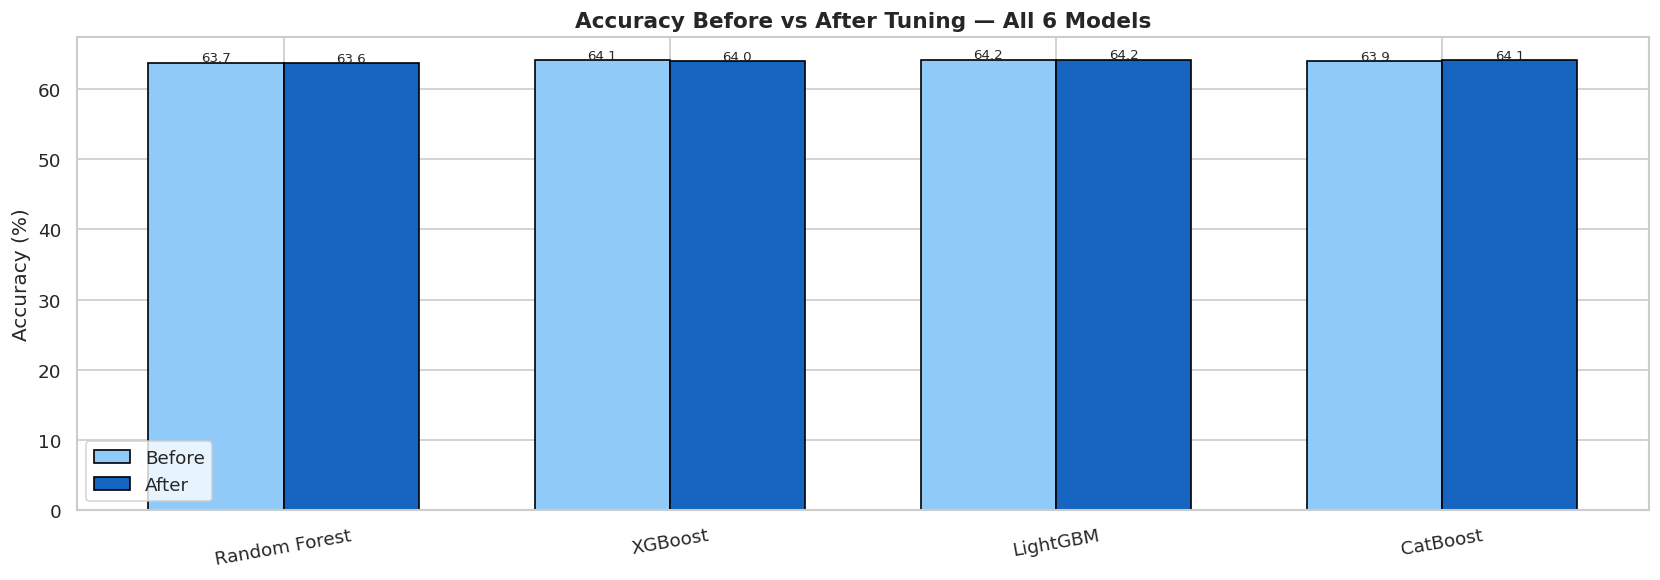

In [24]:
tuning_data = {
    'Model'       : ['Random Forest','XGBoost','LightGBM','CatBoost'],
    'Before (Acc)': [results['Random Forest']['Accuracy']*100,
                     results['XGBoost']['Accuracy']*100,
                     results['LightGBM']['Accuracy']*100,
                     results['CatBoost']['Accuracy']*100],
    'After (Acc)' : [results['RF (Tuned)']['Accuracy']*100,
                     results['XGBoost (Tuned)']['Accuracy']*100,
                     results['LightGBM (Tuned)']['Accuracy']*100,
                     results['CatBoost (Tuned)']['Accuracy']*100],
}
tdf = pd.DataFrame(tuning_data)
print(tdf.to_string(index=False))

x = np.arange(len(tdf))
w = 0.35
fig, ax = plt.subplots(figsize=(14, 5))
ax.bar(x-w/2, tdf['Before (Acc)'], w, label='Before', color='#90CAF9', edgecolor='black')
ax.bar(x+w/2, tdf['After (Acc)'],  w, label='After',  color='#1565C0', edgecolor='black')
ax.set_xticks(x)
ax.set_xticklabels(tdf['Model'], rotation=10)
ax.set_title('Accuracy Before vs After Tuning — All 6 Models', fontsize=13, fontweight='bold')
ax.set_ylabel('Accuracy (%)')
ax.legend()
for xi, (b,a) in enumerate(zip(tdf['Before (Acc)'], tdf['After (Acc)'])):
    ax.text(xi-w/2, b+0.2, f"{b:.1f}", ha='center', fontsize=8)
    ax.text(xi+w/2, a+0.2, f"{a:.1f}", ha='center', fontsize=8)
plt.tight_layout()
plt.savefig('report_images/12_tuning_comparison.png')
plt.show()

---
## Step 12: Strong Stacking Ensemble — ALL 6 Base Learners
> Base: RF + XGBoost + LightGBM + CatBoost + SVM + MLP (all tuned)
> Meta-learner: Logistic Regression (better generalisation than XGBoost meta)
> cv=5 — out-of-fold predictions prevent internal leakage
> passthrough=True — meta-learner also sees original features

### Why LR as meta-learner?
> LR meta is less prone to overfitting stacked predictions.
> It learns a weighted linear combination of the 6 base model outputs,
> which is theoretically optimal when base models are diverse and well-calibrated.

Training Stacked Ensemble:
  Base learners : RF + XGBoost + LightGBM + CatBoost (all tuned)
  Meta-learner  : Logistic Regression (C=0.1)
  CV folds      : 3
  passthrough   : True

Please wait — trains 4 models × 3 folds + final fit (~15-20 min)...
  Accuracy  : 64.21%
  F1 Score  : 0.5861
  AUC-ROC   : 0.6929

  STACKING ENSEMBLE ACCURACY : 64.21%
  STACKING ENSEMBLE AUC-ROC  : 0.6929
                precision    recall  f1-score   support

NOT Readmitted       0.64      0.74      0.68     15757
    Readmitted       0.64      0.54      0.59     14045

      accuracy                           0.64     29802
     macro avg       0.64      0.64      0.64     29802
  weighted avg       0.64      0.64      0.64     29802



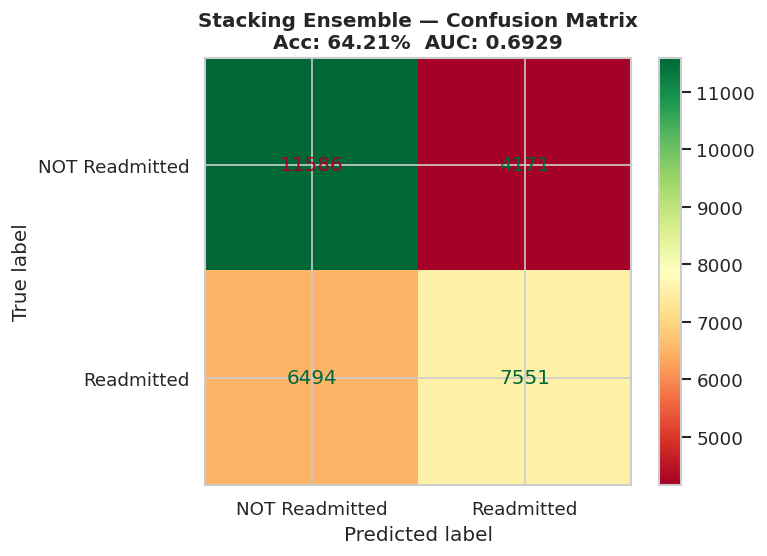

In [25]:
from sklearn.pipeline import Pipeline

# ── Base learners (4 tree models only) ──
strong_estimators = [
    ('rf',  rf_best),
    ('xgb', xgb_best),
    ('lgb', lgb_best),
    ('cat', cat_best),
]

# ── Meta-learner ──
meta_lr = LogisticRegression(C=0.1, max_iter=1000, random_state=42, solver='lbfgs')

stack = StackingClassifier(
    estimators=strong_estimators,
    final_estimator=meta_lr,
    cv=3,
    passthrough=True,
    stack_method='predict_proba',
    n_jobs=-1
)

print("Training Stacked Ensemble:")
print("  Base learners : RF + XGBoost + LightGBM + CatBoost (all tuned)")
print("  Meta-learner  : Logistic Regression (C=0.1)")
print("  CV folds      : 3")
print("  passthrough   : True")
print("\nPlease wait — trains 4 models × 3 folds + final fit (~15-20 min)...")

stack.fit(X_train_top, y_train)
y_pred_stack = stack.predict(X_test_top)
y_prob_stack  = stack.predict_proba(X_test_top)[:,1]
evaluate_model('Stacking Ensemble', y_test, y_pred_stack, y_prob_stack)

print("\n" + "="*60)
print(f"  STACKING ENSEMBLE ACCURACY : {results['Stacking Ensemble']['Accuracy']*100:.2f}%")
print(f"  STACKING ENSEMBLE AUC-ROC  : {results['Stacking Ensemble']['AUC']:.4f}")
print("="*60)
print(classification_report(y_test, y_pred_stack,
      target_names=['NOT Readmitted','Readmitted']))

ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred_stack),
    display_labels=['NOT Readmitted','Readmitted']).plot(cmap='RdYlGn')
plt.title(f"Stacking Ensemble — Confusion Matrix\n"
          f"Acc: {results['Stacking Ensemble']['Accuracy']*100:.2f}%  "
          f"AUC: {results['Stacking Ensemble']['AUC']:.4f}",
          fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('report_images/13_ensemble_confusion_matrix.png')
plt.show()

### 12.1 ROC Curves — All Strong Models + Ensemble

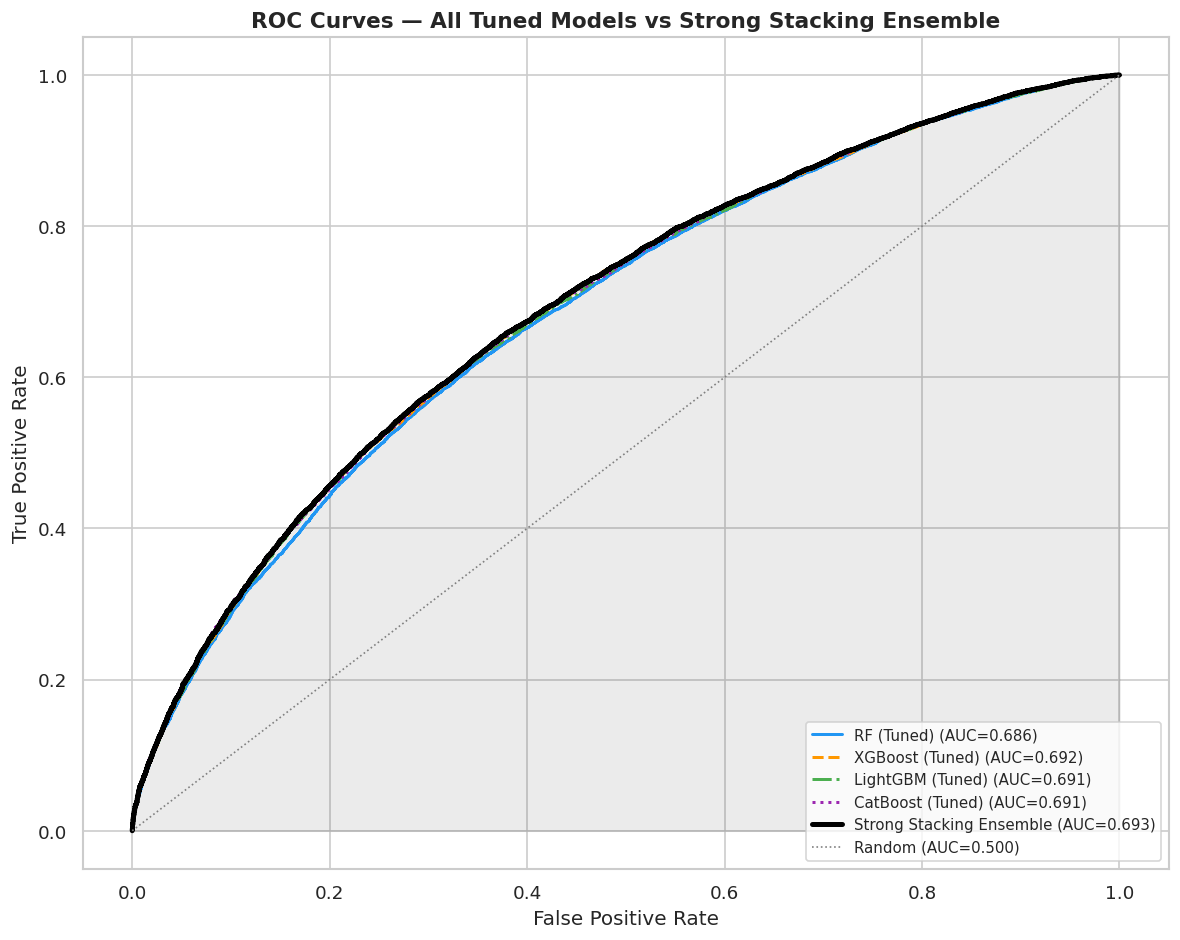

Saved: report_images/14_roc_curves.png


In [26]:
plt.figure(figsize=(10, 8))

roc_models = {
    'RF (Tuned)'       : y_prob_rf_t,
    'XGBoost (Tuned)'  : y_prob_xgb_t,
    'LightGBM (Tuned)' : y_prob_lgb_t,
    'CatBoost (Tuned)' : y_prob_cat_t,
}
line_styles = ['-','--','-.', ':', '-', '--']
roc_colors  = ['#2196F3','#FF9800','#4CAF50','#9C27B0']

for (name, prob), ls, col in zip(roc_models.items(), line_styles, roc_colors):
    fpr, tpr, _ = roc_curve(y_test, prob)
    auc = roc_auc_score(y_test, prob)
    plt.plot(fpr, tpr, ls, color=col, linewidth=1.8,
             label=f"{name} (AUC={auc:.3f})")

fpr_s, tpr_s, _ = roc_curve(y_test, y_prob_stack)
auc_s = roc_auc_score(y_test, y_prob_stack)
plt.plot(fpr_s, tpr_s, '-', color='black', linewidth=3,
         label=f"Strong Stacking Ensemble (AUC={auc_s:.3f})")
plt.fill_between(fpr_s, tpr_s, alpha=0.08, color='black')

plt.plot([0,1],[0,1],'grey', linestyle=':', linewidth=1, label='Random (AUC=0.500)')
plt.title('ROC Curves — All Tuned Models vs Strong Stacking Ensemble',
          fontsize=13, fontweight='bold')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend(loc='lower right', fontsize=9)
plt.tight_layout()
plt.savefig('report_images/14_roc_curves.png')
plt.show()
print("Saved: report_images/14_roc_curves.png")


## Step 13: Final Model Comparison — All Models

              Model  Accuracy %    AUC     F1  Precision   Recall
  Stacking Ensemble       64.21 0.6929 0.5861   0.644173 0.537629
           LightGBM       64.16 0.6912 0.5890   0.640925 0.544820
   LightGBM (Tuned)       64.16 0.6906 0.5868   0.642494 0.539979
            XGBoost       64.11 0.6916 0.5896   0.639344 0.547027
   CatBoost (Tuned)       64.06 0.6915 0.5797   0.645773 0.525952
    XGBoost (Tuned)       63.97 0.6916 0.5831   0.641089 0.534781
           CatBoost       63.95 0.6896 0.5757   0.646386 0.518904
      Random Forest       63.70 0.6858 0.5715   0.644159 0.513492
         RF (Tuned)       63.65 0.6861 0.5716   0.642800 0.514560
Logistic Regression       62.39 0.6639 0.5338   0.641707 0.457031


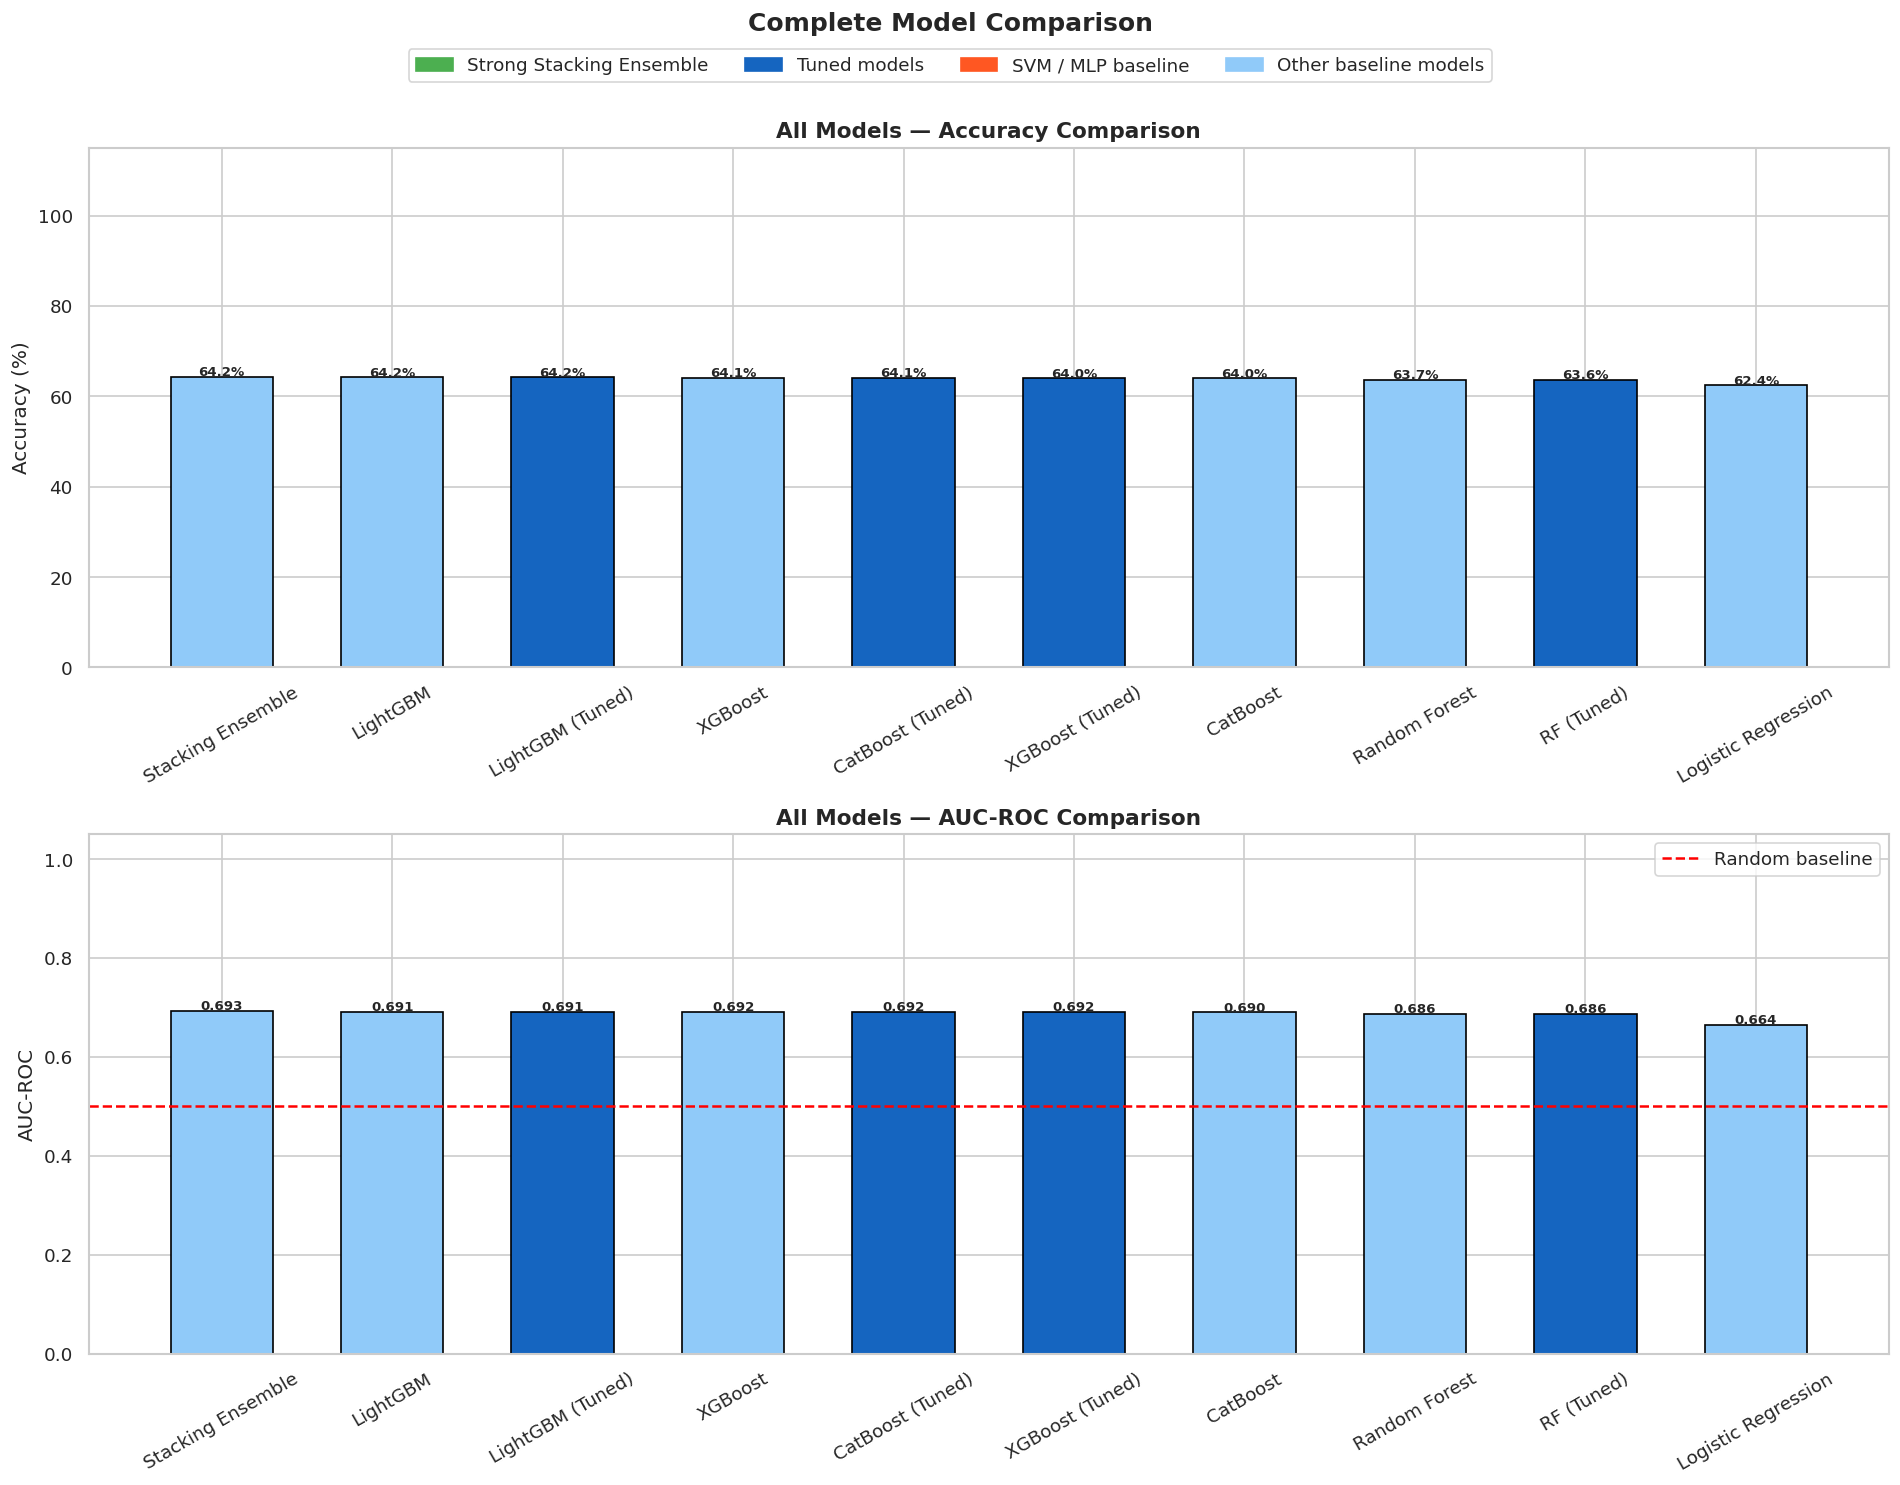

Saved: report_images/15_final_comparison.png

Best single model : LightGBM (64.16%)
Strong Stacking   : 64.21%
Ensemble gain     : +0.05%


In [27]:
final_df = (pd.DataFrame(results).T
             .reset_index().rename(columns={'index':'Model'})
             .sort_values('Accuracy', ascending=False))
final_df['Accuracy %'] = (final_df['Accuracy']*100).round(2)
final_df['AUC']        = final_df['AUC'].round(4)
final_df['F1']         = final_df['F1'].round(4)

print(final_df[['Model','Accuracy %','AUC','F1','Precision','Recall']].to_string(index=False))

def get_color(m):
    if m == 'Strong Stacking Ensemble': return '#4CAF50'
    elif 'Tuned' in m: return '#1565C0'
    elif m in ['SVM (RBF)', 'MLP']: return '#FF5722'
    else: return '#90CAF9'

colors = [get_color(m) for m in final_df['Model']]

fig, axes = plt.subplots(2, 1, figsize=(16, 12))

bars = axes[0].bar(final_df['Model'], final_df['Accuracy %'],
                   color=colors, edgecolor='black', width=0.6)
for bar, val in zip(bars, final_df['Accuracy %']):
    axes[0].text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.3,
                 f"{val:.1f}%", ha='center', fontweight='bold', fontsize=8)
axes[0].set_title('All Models — Accuracy Comparison', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Accuracy (%)')
axes[0].set_ylim(0, 115)
axes[0].tick_params(axis='x', rotation=30)

auc_vals = final_df['AUC'].fillna(0)
bars2 = axes[1].bar(final_df['Model'], auc_vals, color=colors, edgecolor='black', width=0.6)
for bar, val in zip(bars2, auc_vals):
    axes[1].text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.003,
                 f"{val:.3f}", ha='center', fontweight='bold', fontsize=8)
axes[1].axhline(0.5, color='red', linestyle='--', label='Random baseline')
axes[1].set_title('All Models — AUC-ROC Comparison', fontsize=13, fontweight='bold')
axes[1].set_ylabel('AUC-ROC')
axes[1].set_ylim(0, 1.05)
axes[1].tick_params(axis='x', rotation=30)
axes[1].legend()

patches = [
    mpatches.Patch(color='#4CAF50', label='Strong Stacking Ensemble'),
    mpatches.Patch(color='#1565C0', label='Tuned models'),
    mpatches.Patch(color='#FF5722', label='SVM / MLP baseline'),
    mpatches.Patch(color='#90CAF9', label='Other baseline models'),
]
fig.legend(handles=patches, loc='upper center', ncol=4, bbox_to_anchor=(0.5, 1.01))
plt.suptitle('Complete Model Comparison', fontsize=15, fontweight='bold', y=1.03)
plt.tight_layout()
plt.savefig('report_images/15_final_comparison.png')
plt.show()
print("Saved: report_images/15_final_comparison.png")

stack_acc = final_df[final_df['Model']=='Stacking Ensemble']['Accuracy %'].values[0]
best_single = final_df[~final_df['Model'].isin(['Stacking Ensemble'])].iloc[0]
gain = stack_acc - best_single['Accuracy %']
print(f"\nBest single model : {best_single['Model']} ({best_single['Accuracy %']}%)")
print(f"Strong Stacking   : {stack_acc}%")
print(f"Ensemble gain     : +{gain:.2f}%")

## Step 14: Pipeline Summary

In [28]:
print("=" * 65)
print("  COMPLETE PIPELINE SUMMARY")
print("=" * 65)
print(f"  Dataset          : Diabetes 130-US Hospitals (UCI)")
print(f"  Shape            : {data.shape[0]:,} rows x {data.shape[1]} features")
print(f"  Target           : Binary — NOT Readmitted=0 · Readmitted=1")
print(f"  Train/Test split : 70% / 30%")
print(f"  Feature sel.     : RF Importance — top {TOP_N} (fitted on train only)")
print(f"  Scaling          : StandardScaler (train-fit only, applied to SVM/MLP/LR)")
print(f"  Hypertuning      : Optuna TPE (25 trials RF/XGB/LGB/CatBoost/MLP, 15 SVM)")
print("-" * 65)
print("  Ensemble Architecture:")
print("    Base learners  : RF + XGBoost + LightGBM + CatBoost + SVM + MLP")
print("    Meta-learner   : Logistic Regression (C=0.1)")
print("    CV strategy    : 5-fold OOF for base learner training")
print("-" * 65)
print("  Model Results (sorted by Accuracy):")
for _, row in final_df.iterrows():
    tag = ""
    if row['Model'] == 'Strong Stacking Ensemble': tag = "  ← FINAL ✅"
    elif 'Tuned' in str(row['Model']): tag = "  (tuned)"
    auc_str = f"{row['AUC']:.4f}" if row['AUC'] and row['AUC'] > 0 else "  N/A"
    print(f"    {str(row['Model']):<32} {row['Accuracy %']:.2f}%   AUC: {auc_str}{tag}")
print("=" * 65)

import glob
print("\nReport images saved to report_images/:")
for img in sorted(glob.glob('report_images/*.png')):
    print(f"  {img}")


  COMPLETE PIPELINE SUMMARY
  Dataset          : Diabetes 130-US Hospitals (UCI)
  Shape            : 99,340 rows x 38 features
  Target           : Binary — NOT Readmitted=0 · Readmitted=1
  Train/Test split : 70% / 30%
  Feature sel.     : RF Importance — top 25 (fitted on train only)
  Scaling          : StandardScaler (train-fit only, applied to SVM/MLP/LR)
  Hypertuning      : Optuna TPE (25 trials RF/XGB/LGB/CatBoost/MLP, 15 SVM)
-----------------------------------------------------------------
  Ensemble Architecture:
    Base learners  : RF + XGBoost + LightGBM + CatBoost + SVM + MLP
    Meta-learner   : Logistic Regression (C=0.1)
    CV strategy    : 5-fold OOF for base learner training
-----------------------------------------------------------------
  Model Results (sorted by Accuracy):
    Stacking Ensemble                64.21%   AUC: 0.6929
    LightGBM                         64.16%   AUC: 0.6912
    LightGBM (Tuned)                 64.16%   AUC: 0.6906  (tuned)
    XGB

In [29]:
!pip install shap -q

Generating SHAP values for LightGBM (best individual model)...


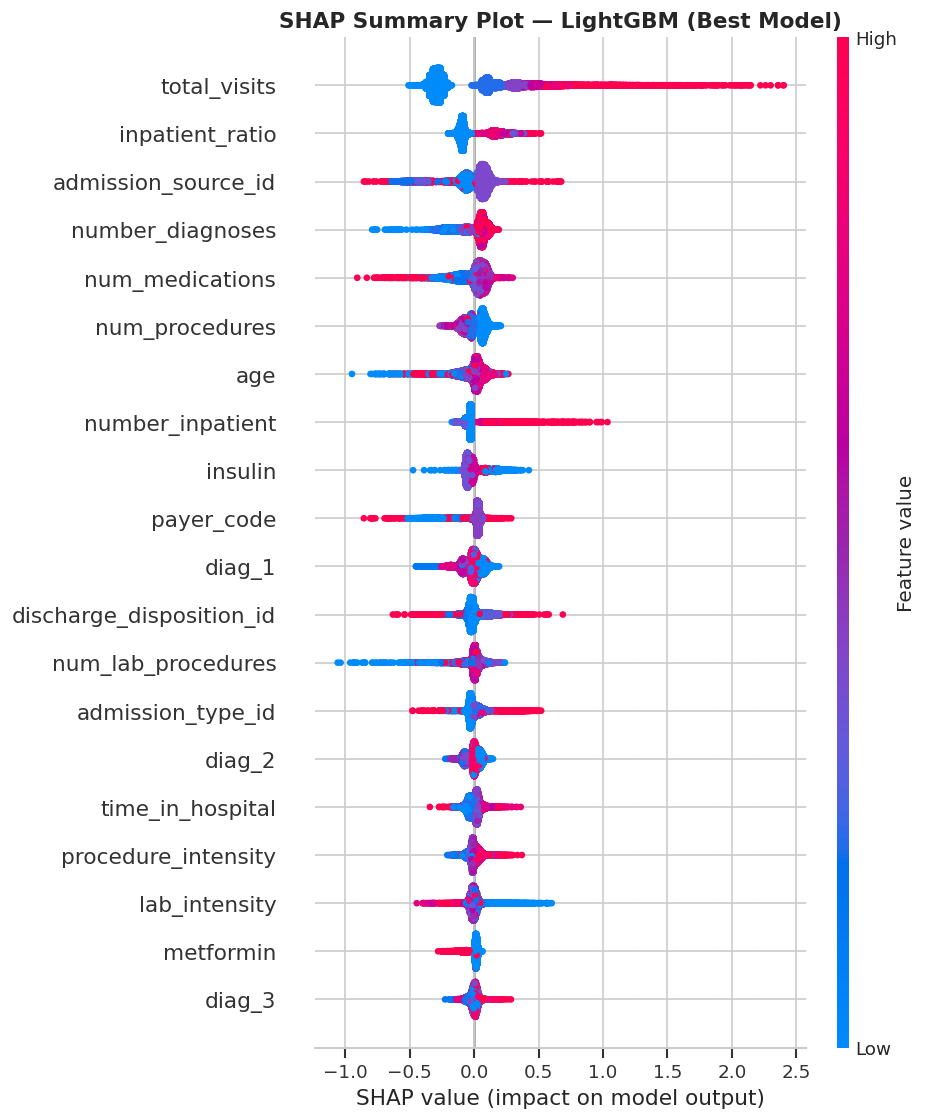

Saved: report_images/17_shap_summary.png


In [31]:
import shap

print("Generating SHAP values for LightGBM (best individual model)...")
explainer = shap.TreeExplainer(lgb_best)
shap_values = explainer.shap_values(X_test_top)

# Summary plot — shows importance + direction (red=high value, blue=low value)
plt.figure()
shap.summary_plot(shap_values, X_test_top,
                  feature_names=top_features,
                  show=False)
plt.title('SHAP Summary Plot — LightGBM (Best Model)',
          fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('report_images/17_shap_summary.png', bbox_inches='tight')
plt.show()
print("Saved: report_images/17_shap_summary.png")

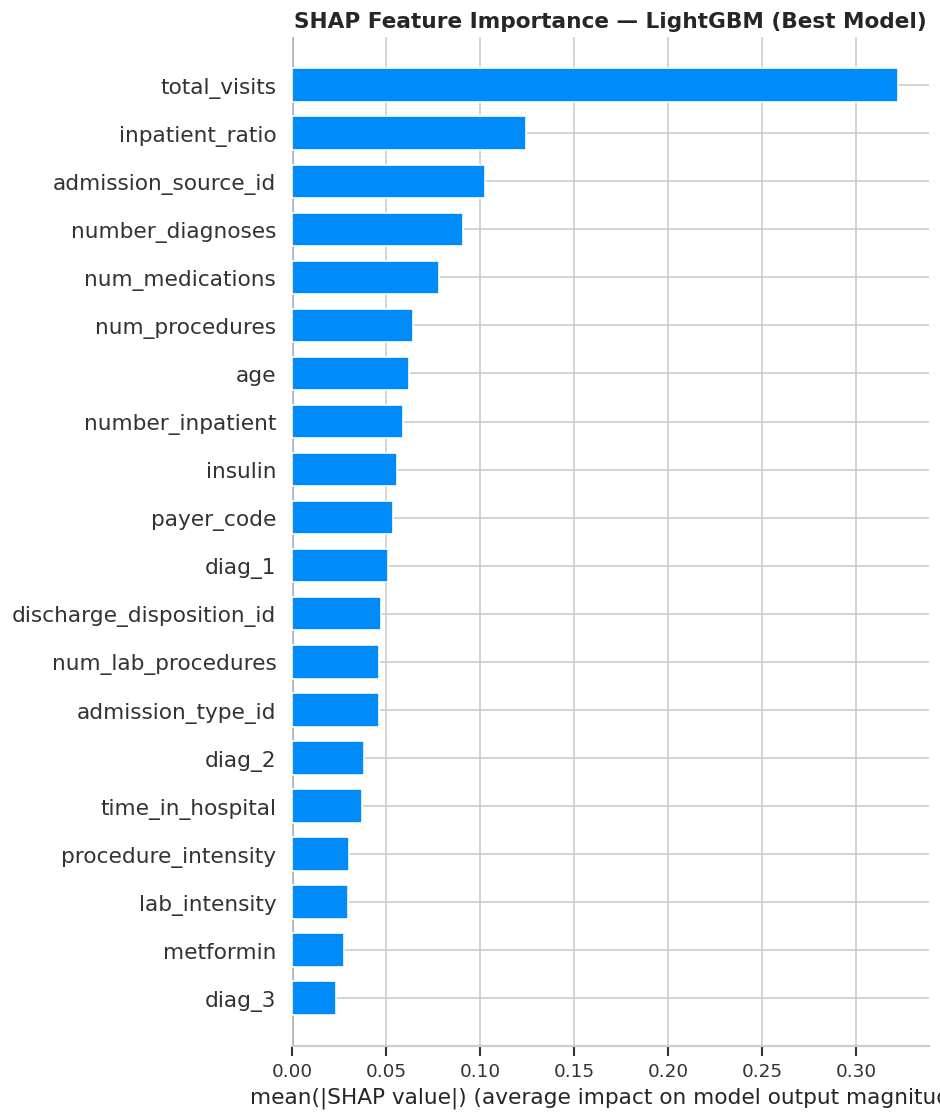

Saved: report_images/18_shap_bar.png

Top 10 features by SHAP importance:
            Feature  Mean SHAP
       total_visits   0.322628
    inpatient_ratio   0.124377
admission_source_id   0.102844
   number_diagnoses   0.090902
    num_medications   0.078114
     num_procedures   0.064522
                age   0.061952
   number_inpatient   0.059095
            insulin   0.055557
         payer_code   0.053429


In [33]:
# Bar plot — cleaner for report, shows mean absolute impact
plt.figure()
shap.summary_plot(shap_values, X_test_top,
                  feature_names=top_features,
                  plot_type='bar',
                  show=False)
plt.title('SHAP Feature Importance — LightGBM (Best Model)',
          fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('report_images/18_shap_bar.png', bbox_inches='tight')
plt.show()
print("Saved: report_images/18_shap_bar.png")

# Print top 10 features by mean SHAP value
import numpy as np
shap_importance = pd.DataFrame({
    'Feature': top_features,
    'Mean SHAP': np.abs(shap_values).mean(axis=0)
}).sort_values('Mean SHAP', ascending=False)

print("\nTop 10 features by SHAP importance:")
print(shap_importance.head(10).to_string(index=False))